# 01 · Data: Tobacco3482 and SAD-Syn

This notebook shows where both datasets come from, checks that they are built as Section 3 describes, and
reproduces every figure in Section 3. It runs on CPU.

**Modes.** Set the flags in the next cell:

- **Default (all flags `False`).** Downloads Tobacco3482 at the pinned revision, rebuilds its split, walks through
  how SAD-Syn is generated, runs the structural checks, and redraws the figures. It uses the committed manifests
  and the OCR text in the data bundle. This takes about 5 minutes on Colab.
- **`REBUILD_SAD_SYN = True`** regenerates all 3,000 SAD-Syn pages with OCR: 5 minutes on 10 CPU cores, about 25
  minutes on Colab's 2.
- **`RERUN_TOBACCO_OCR = True`** re-OCRs the 3,482 Tobacco3482 pages: 9 minutes on 10 cores, about 45 minutes on
  Colab.
- **`RUN_OCR_EXPERIMENTS = True`** reruns the degradation calibration and the font screen (Tables 3.4–3.6). This
  takes about 20 minutes.

The three OCR flags install Tesseract. Colab's package gives Tesseract 4.1, while the report used 5.5.2, so rebuilt
OCR text differs slightly from the committed text (Section 6.2).

| Section | Backs report section |
|---|---|
| 1. Tobacco3482: source, split, OCR | 3.1, Table 3.1 |
| 2. SAD-Syn: one pair from the generator | 3.2.1–3.2.3, Table 3.2 |
| 3. SAD-Syn: templates, split and structure checks | 3.2.3–3.2.6, Table 3.3 |
| 4. Ground truth vs the generator (pre-test check 1) | 7 (protocol) |
| 5. Optional rebuilds and OCR experiments | 3.2.5, 3.2.7, 6.2 |
| 6. Figures | Figures 3.1–3.7 |

In [1]:
REBUILD_SAD_SYN = False      # regenerate and OCR all 3,000 SAD-Syn pages
RERUN_TOBACCO_OCR = False    # OCR all 3,482 Tobacco3482 pages again
RUN_OCR_EXPERIMENTS = False  # degradation calibration and font screen (Tables 3.4-3.6)

## Setup

Runs in a fresh Colab runtime or locally from a clone of the repository.

**On Colab**, this cell does three things:

1. It gets the code: it clones the repository at the submission tag, or unpacks the code zip if `CODE_ZIP` is set
   (for when the repository is not public).
2. It installs the few packages Colab lacks, pinned in `requirements-colab.txt`. Colab's own torch, NumPy and pandas
   are kept, and their versions are printed below.
3. It puts the code on the import path.

**Locally**, the cell only finds the repository root. Install with `uv sync` first.

In [2]:
REPO_URL = 'https://github.com/upretisaurav/doc-verify.git'
TAG = 'v1.0-submission'
CODE_ZIP = None  # if the repository is not public: path to the submitted code zip, e.g. '/content/doc-verify.zip'

import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    ROOT = Path('/content/doc-verify')
    if not ROOT.exists():
        if CODE_ZIP:
            subprocess.run(['unzip', '-q', CODE_ZIP, '-d', '/content'], check=True)
        else:
            subprocess.run(['git', 'clone', '-q', '--depth', '1', '--branch', TAG, REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT / 'requirements-colab.txt')],
                   check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for path in (ROOT / 'src', ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)

import importlib.metadata
import platform

import torch
import transformers

transformers.logging.set_verbosity_error()  # hide checkpoint-loading reports
transformers.logging.disable_progress_bar()

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
print(f'Python {platform.python_version()} | torch {torch.__version__} | GPU: {gpu}')
print({p: importlib.metadata.version(p) for p in ('timm', 'transformers', 'scikit-learn', 'numpy', 'pandas')})

Python 3.13.18 | torch 2.14.1+cpu | GPU: none
{'timm': '1.0.30', 'transformers': '5.18.0', 'scikit-learn': '1.9.1', 'numpy': '2.4.6', 'pandas': '2.2.3'}


In [3]:
NEED_TESSERACT = REBUILD_SAD_SYN or RERUN_TOBACCO_OCR or RUN_OCR_EXPERIMENTS
if IN_COLAB and NEED_TESSERACT:
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'tesseract-ocr'], check=True)
if NEED_TESSERACT:
    print(subprocess.run(['tesseract', '--version'], capture_output=True, text=True, check=True).stdout.splitlines()[0])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from doc_verify.assets import fetch_bundle
from doc_verify.config import DATA_DIR, FIGURES_DIR, RESULTS_DIR

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK_2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'font.size': 10,
    'axes.edgecolor': INK_2, 'axes.labelcolor': INK, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

tobacco = pd.read_csv(RESULTS_DIR / 'manifests' / 'tobacco3482' / 'manifest.csv')
sad = pd.read_csv(RESULTS_DIR / 'manifests' / 'sad_syn' / 'manifest.csv')
bundle = fetch_bundle()  # 224 x 224 pages and the OCR text of every page (66 MB, from the GitHub release)
print(len(tobacco), 'Tobacco3482 pages,', len(sad), 'SAD-Syn pages')

downloading doc_verify_bundle.zip ...
3482 Tobacco3482 pages, 3000 SAD-Syn pages


## 1. Tobacco3482: source, split and OCR

**Source.** The pages come from the Hugging Face copy `maveriq/tobacco3482`, pinned to revision `5ee64c0e`
(1.6 GB). Pinning matters because the split is a seeded shuffle of each class's pages taken in source order: a copy
with pages in another order would give a different split (`doc_verify.tobacco.download_tobacco`).

**Split.** Within each class, the pages are shuffled with seed 42 and cut 70/15/15 (`tobacco.assign_splits`).
Recomputing the split from the download must give exactly the split in the committed manifest.

In [4]:
from doc_verify.tobacco import (
    DOC_TYPE_NAMES,
    assign_splits,
    download_tobacco,
    load_tobacco,
    to_200_dpi,
)

download_tobacco()
raw = load_tobacco()
labels = raw['label']
splits = assign_splits(labels)
assert splits == tobacco.split.tolist(), 'split does not reproduce'
assert [DOC_TYPE_NAMES[raw.features['label'].names[label]] for label in labels] == tobacco.doc_type.tolist()
print('split and labels reproduce for all', len(splits), 'pages')
table = pd.crosstab(tobacco.doc_type, tobacco.split)[['train', 'val', 'test']]
table.loc['total'] = table.sum()
table.assign(total=table.sum(axis=1))  # Table 3.1

Generating train split:   0%|          | 0/3482 [00:00<?, ? examples/s]

split and labels reproduce for all 3482 pages


split,train,val,test,total
doc_type,,,,
advertisement,161,34,35,230
email,419,90,90,599
form,302,65,64,431
letter,397,85,85,567
memo,434,93,93,620
news,132,28,28,188
note,141,30,30,201
report,186,40,39,265
resume,84,18,18,120


**OCR.** Every page is converted to grayscale and brought to about 200 DPI: the few 300 DPI scans are scaled to
two-thirds. The page is saved, and that saved file is read with Tesseract (`tobacco.build_tobacco`). The manifest
records each page's mean word confidence.

The table below gives the summary used in Section 3.1. With `RERUN_TOBACCO_OCR`, the OCR runs again into
`data/rebuilt/`, and the new text is compared with the committed text.

In [5]:
summary = tobacco.groupby('doc_type').agg(pages=('split', 'size'),
                                          no_text=('mean_confidence', lambda c: c.isna().sum()),
                                          median_confidence=('mean_confidence', 'median'))
display(summary.round(1))

if RERUN_TOBACCO_OCR:
    from doc_verify.tobacco import build_tobacco

    rebuilt = build_tobacco(out_dir=DATA_DIR / 'rebuilt' / 'tobacco3482')
    same = [(DATA_DIR / 'rebuilt' / 'tobacco3482' / p).read_text() == (bundle / 'tobacco3482' / p).read_text()
            for p in rebuilt.text_path]
    print(f'OCR text identical to the committed text on {np.mean(same):.1%} of pages')

,pages,no_text,median_confidence
doc_type,,,
advertisement,230,6,64.9
email,599,0,90.6
form,431,2,73.9
letter,567,0,90.3
memo,620,0,89.7
news,188,1,81.9
note,201,6,46.6
report,265,0,91.8
resume,120,0,91.7


## 2. SAD-Syn: one pair from the generator

SAD-Syn is generated from fixed seeds, so every document can be rebuilt without rendering anything:
`sad_syn.dataset.plan_documents(1500)` returns all 3,000 documents in build order, each with its template, degradation
seed, split and pair id.

Here is the first pair. The clean and the altered document are **two separately generated documents** that share a
template and a degradation seed (Section 3.2.3). The altered one has one field changed so that exactly one
consistency rule breaks.

In [6]:
from sad_syn.dataset import plan_documents
from sad_syn.doc_types import DOC_TYPES

jobs = plan_documents(1500)
jobs_by_path = {str(job['image_path']): job for job in jobs}
clean_job, altered_job = jobs[0], jobs[1]
assert clean_job['pair_id'] == altered_job['pair_id'] and clean_job['template'] == altered_job['template']

altered = altered_job['doc']
rules = DOC_TYPES[altered['doc_type']].check_rules
print('document type:', altered['doc_type'], '| template:', altered_job['template']['template_id'],
      '| degradation seed:', altered_job['seed'])
print('kind:', altered['inconsistency_type'], '| field changed:', altered['altered_field'],
      '|', altered['original_value'], '->', altered[altered['altered_field']])
pd.DataFrame({'clean': rules(clean_job['doc']), 'altered': rules(altered)})  # True = rule holds

document type: offer_letter | template: offer_letter_17 | degradation seed: 10000
kind: altered_date | field changed: payment_deadline | 2026-06-07 -> 2026-08-07


,clean,altered
date_order,True,False
completion_matches_duration,True,True
total_matches_fee,True,True
deposit_below_fee,True,True
deposits_match,True,True
university_names_match,True,True


Rendering and degrading the pair from the plan reproduces the dataset's pages exactly:

1. Render the page at 200 DPI.
2. Degrade it with the seed's strength.
3. Shrink it to the model's 224 × 224 input, as training does.

The result is compared with the bundle's pages pixel by pixel. On another Pillow or font-rendering version a few
pixels may differ.

offer_letter_17_00000_clean.png | 224 x 224 pixels equal to the dataset page: 100.00%
offer_letter_17_00000_altered.png | 224 x 224 pixels equal to the dataset page: 100.00%


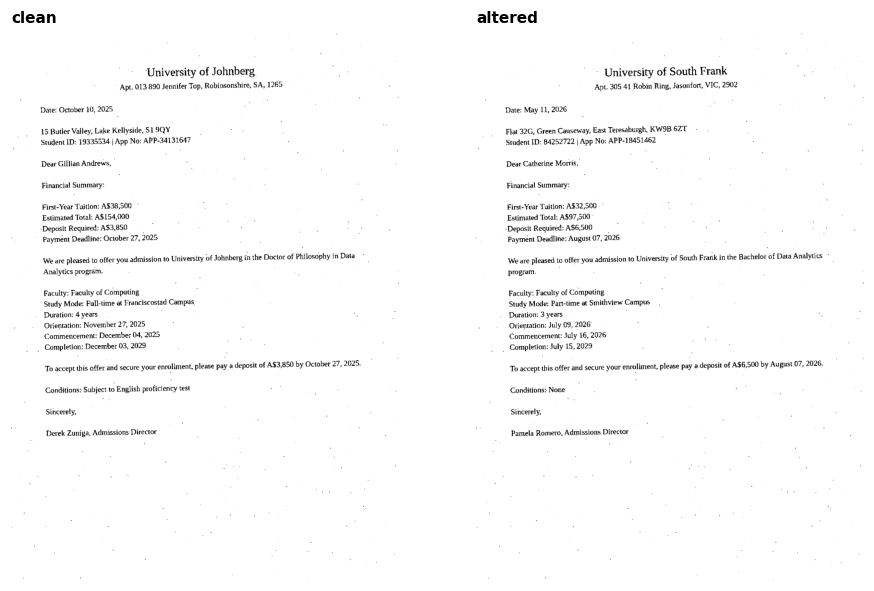

In [7]:
import tempfile

from doc_verify.data import load_image
from sad_syn.degrade import degrade, draw_strength
from sad_syn.doc_types import render_document


def render_job(job):
    """The dataset page for one planned document: render at 200 DPI, then degrade with its seed's strength."""
    return degrade(render_document(job['doc'], job['template']), draw_strength(job['seed']), job['seed'])


fig, axes = plt.subplots(1, 2, figsize=(10, 7))
for ax, job in zip(axes, (clean_job, altered_job)):
    page = render_job(job)
    with tempfile.NamedTemporaryFile(suffix='.png') as tmp:
        page.save(tmp.name)
        small = np.asarray(load_image(tmp.name))
    released = np.asarray(Image.open(bundle / 'sad_syn' / job['image_path']))
    print(job['image_path'].name, f'| 224 x 224 pixels equal to the dataset page: {(small == released).mean():.2%}')
    ax.imshow(page, cmap='gray')
    ax.set_title(job['image_path'].stem.split('_')[-1], loc='left')
    ax.axis('off')
plt.show()

**Rule test.** For every document type, 200 clean documents must pass every rule, and 200 altered documents of each
kind must break exactly their intended rule and no other (`sad_syn.doc_types.rule_test`). The report's build used
1,000 of each, and `tests/test_rules.py` runs the same check.

In [8]:
from sad_syn.doc_types import rule_test
from sad_syn.generate import set_seed

set_seed(0)
pd.DataFrame({doc_type: rule_test(doc_type, 200) for doc_type in DOC_TYPES}).T  # documents passing the test, of 200

,clean,altered_date,altered_amount,institution_mismatch,total_mismatch
offer_letter,200,200,200,200,200
transcript,200,200,200,200,200
bank_statement,200,200,200,200,200


## 3. SAD-Syn: templates, split and structure checks

**Templates.** For each document type, 20 layout templates are generated from a fixed seed, varying:

- the font, margin, font size and line spacing;
- the header alignment and date format;
- the section order.

They are split **by template**, 14/3/3 (`sad_syn.templates.split_templates`). The split raises an error if any font
is missing from training, or if a font repeats within validation or test.

In [9]:
from sad_syn.templates import split_templates

rows = [{'doc_type': doc_type, 'split': split, **template}
        for doc_type, kind in DOC_TYPES.items()
        for split, templates in split_templates(doc_type, kind.templates).items()
        for template in templates]
templates = pd.DataFrame(rows)
display(templates.groupby(['doc_type', 'split']).size().unstack()[['train', 'val', 'test']])
templates.groupby(['split', 'font']).size().unstack(fill_value=0).loc[['train', 'val', 'test']]

split,train,val,test
doc_type,,,
bank_statement,14,3,3
offer_letter,14,3,3
transcript,14,3,3


font,Lato-Regular.ttf,LiberationSans-Regular.ttf,LiberationSerif-Regular.ttf,PTSans-Regular.ttf,PTSerif-Regular.ttf
split,,,,,
train,10,7,9,9,7
val,0,2,3,1,3
test,2,3,0,2,2


**Structure checks on the built dataset (the committed manifest):**

- every pair has exactly one clean and one altered page, with the same template, seed, strength and split;
- no template appears in two splits;
- the four kinds are balanced as in Table 3.3.

**Label-gap test (Section 3.2.6).** The degradation never sees the label, so clean and altered pages should be read
equally well by OCR. Their accuracy (the share of key printed values OCR found) is compared pair by pair with a
paired t-test.

In [10]:
from scipy import stats

by_pair = sad.groupby('pair_id')
assert (by_pair.size() == 2).all() and (by_pair.label.nunique() == 2).all()
for column in ('template', 'seed', 'strength', 'split', 'doc_type'):
    assert (by_pair[column].nunique() == 1).all(), column
assert (sad.groupby('template').split.nunique() == 1).all()
print('pairing and split checks pass:', sad.pair_id.nunique(), 'pairs,', sad.template.nunique(), 'templates')

altered_pages = sad[sad.label == 'altered']
kinds = pd.crosstab(altered_pages.split, altered_pages.inconsistency_type).loc[['train', 'val', 'test']]
display(kinds)  # Table 3.3

sad['ocr_accuracy'] = sad.copies_read / sad.copies_total
wide = sad.pivot(index='pair_id', columns='label', values='ocr_accuracy')
result = stats.ttest_rel(wide.clean, wide.altered)
print(f'OCR accuracy: clean {wide.clean.mean():.3f}, altered {wide.altered.mean():.3f}; '
      f'paired t-test over {len(wide)} pairs p = {result.pvalue:.2f}')

pairing and split checks pass: 1500 pairs, 60 templates


inconsistency_type,altered_amount,altered_date,institution_mismatch,total_mismatch
split,,,,
train,252,294,252,252
val,54,63,54,54
test,54,63,54,54


OCR accuracy: clean 0.916, altered 0.915; paired t-test over 1500 pairs p = 0.67


## 4. Ground truth vs the generator (pre-test check 1)

Before the test split was opened, one question had to be ruled out: were any labels or text attached to the wrong
document? This is `doc_verify.checks.ground_truth_check`. For every validation page, it compares the labels served
by the training loader with the manifest and with the document rebuilt from the plan. It also checks two further
things:

- every altered page breaks its intended rule, and no clean page breaks any rule;
- where OCR read every evidence value, all of it lies within the 425 tokens the text branch reads.

In [11]:
from doc_verify.checks import ground_truth_check
from doc_verify.data import KIND_CLASSES, load_pages

val_pages = load_pages(('val',), bundle)
check = ground_truth_check(val_pages, data_root=bundle)
kind_index = {name: i for i, name in enumerate(KIND_CLASSES)}
readable = check.evidence_end_token.notna()
print('pages:', len(check))
print('served labels match the manifest:',
      bool(((check.served_auth == (check.manifest_label == 'altered')) &
            (check.served_kind == check.manifest_kind.map(kind_index))).all()))
print('manifest matches the generated document:', bool((check.manifest_kind == check.generated_kind).all()))
print('every page breaks its expected rule (and clean pages none):', bool(check.expected_rule_broken.all()))
print(f'OCR read all evidence on {readable.mean():.1%} of pages; of those, inside the 425-token windows: '
      f'{check[readable].evidence_in_windows.mean():.1%} (latest evidence ends at token '
      f'{int(check.evidence_end_token.max())})')

pages: 450
served labels match the manifest: True
manifest matches the generated document: True
every page breaks its expected rule (and clean pages none): True
OCR read all evidence on 83.6% of pages; of those, inside the 425-token windows: 100.0% (latest evidence ends at token 381)


## 5. Optional rebuilds and OCR experiments

**`REBUILD_SAD_SYN`** regenerates the whole dataset into `data/rebuilt/sad_syn` with `sad_syn.dataset.build_dataset`:
plan, render, degrade, save, OCR the saved image, and write the manifest. The result is then compared with the
committed manifest. Seeds and strengths must match exactly. OCR counts match closely on the same Tesseract version
(5.5.2), less closely on Colab's 4.1.

In [12]:
if REBUILD_SAD_SYN:
    from sad_syn.dataset import build_dataset

    rebuilt = build_dataset(1500, DATA_DIR / 'rebuilt' / 'sad_syn')
    both = sad.merge(rebuilt, on='image_path', suffixes=('', '_new'))
    assert len(both) == len(sad) and (both.seed == both.seed_new).all() and np.allclose(both.strength, both.strength_new)
    print(f"OCR counts identical on {(both.copies_read == both.copies_read_new).mean():.1%} of pages")
else:
    print('REBUILD_SAD_SYN is False: using the committed manifest.')

REBUILD_SAD_SYN is False: using the committed manifest.


**`RUN_OCR_EXPERIMENTS`** reruns three experiments.

**1. Strength sweep (Table 3.6, top).** 100 offer letters are OCR'd at fixed degradation strengths. Their confidence
is compared with the 567 real Tobacco3482 letters by Kolmogorov–Smirnov distance.

**2. Candidate strength draws (Table 3.6, bottom).** Three ways of drawing a strength per page are compared on 400
offer letters. The chosen draw, uniform 0.7–1.2, is the closest.

**3. Font screen (Table 3.5).** The accepted fonts are re-run through `sad_syn.analysis.font_test`.

In [13]:
if RUN_OCR_EXPERIMENTS:
    from sad_syn.analysis import compare_candidates, compare_confidence, font_test
    from sad_syn.generate import make_letters
    from sad_syn.ocr import page_confidences
    from sad_syn.pipeline import run_ocr, run_ocr_sampled
    from sad_syn.render import template_01
    from sad_syn.templates import FONTS

    letters = load_tobacco('Letter')
    reference = pd.Series(page_confidences(to_200_dpi(example['image']) for example in letters), name='tobacco')
    set_seed(42)
    sweep = run_ocr(make_letters(100), template_01, [0, 0.25, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 1])
    display(compare_confidence(sweep, reference, 'tobacco').round(3))

    set_seed(11)
    candidates = {'A: uniform 0.6-1.0': [(1, 0.6, 1.0)], 'B: uniform 0.7-1.2': [(1, 0.7, 1.2)],
                  'C: 75% 0.6-0.9 + 25% 0.9-1.4': [(0.75, 0.6, 0.9), (0.25, 0.9, 1.4)]}
    offers = make_letters(400)
    results = {name: run_ocr_sampled(offers, template_01, mixture) for name, mixture in candidates.items()}
    display(compare_candidates(results, reference, 'tobacco').round(3))
    display(font_test(FONTS).round(3).T)
else:
    print('RUN_OCR_EXPERIMENTS is False: the tables are in the report (Tables 3.4-3.6).')

RUN_OCR_EXPERIMENTS is False: the tables are in the report (Tables 3.4-3.6).


## 6. Figures for Section 3

Every figure is redrawn from the committed manifests, the bundle's OCR text, the Tobacco3482 download and pages
re-rendered from the SAD-Syn plan, and saved to `reports/figures/`.

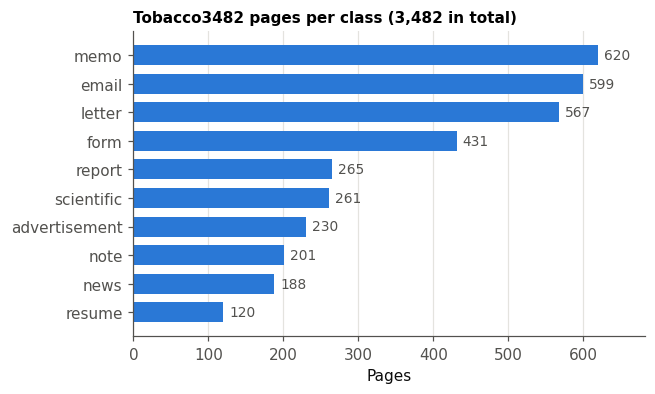

In [14]:
counts = tobacco.doc_type.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.barh(counts.index, counts.values, color=BLUE, height=0.7)
for y, n in enumerate(counts.values):
    ax.text(n + 8, y, f'{n}', va='center', fontsize=9, color=INK_2)
ax.set_xlabel('Pages')
ax.set_title('Tobacco3482 pages per class (3,482 in total)', loc='left')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, counts.max() * 1.1)
fig.savefig(FIGURES_DIR / 'tobacco_class_distribution.png')
plt.show()

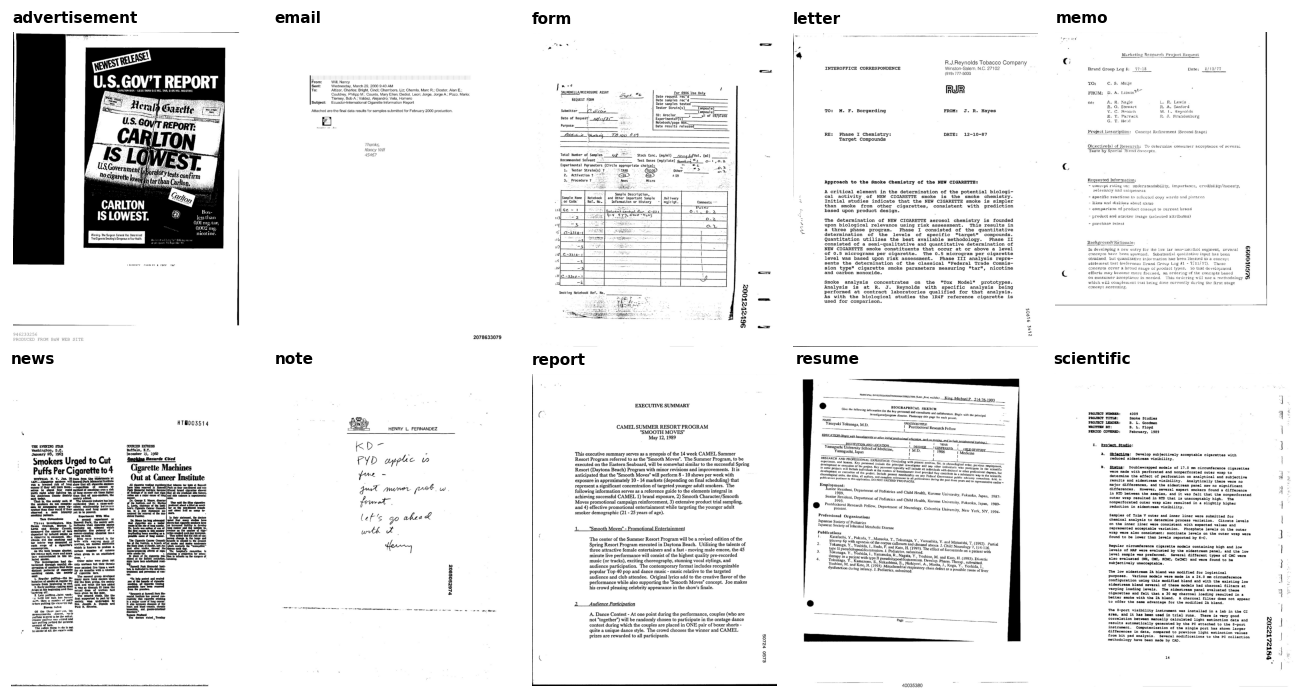

In [15]:
from doc_verify.text_length import load_tokenizer, token_count
from doc_verify.windows import TEXT_WINDOWS, tokens_covered

tokenizer = load_tokenizer()
LIMIT = tokens_covered(TEXT_WINDOWS)
tobacco['tokens'] = [token_count((bundle / 'tobacco3482' / p).read_text(encoding='utf-8'), tokenizer)
                     for p in tobacco.text_path]

fig, axes = plt.subplots(2, 5, figsize=(12, 6.4))
for ax, c in zip(axes.flat, sorted(tobacco.doc_type.unique())):
    candidates = tobacco[(tobacco.doc_type == c) & (tobacco.split == 'train')]
    i = (candidates.tokens - candidates.tokens.median()).abs().idxmin()  # the most typical page of its class
    ax.imshow(to_200_dpi(raw[int(i)]['image'].convert('L')), cmap='gray', vmin=0, vmax=255)
    ax.set_title(c, loc='left')
    ax.axis('off')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tobacco_samples.png')
plt.show()

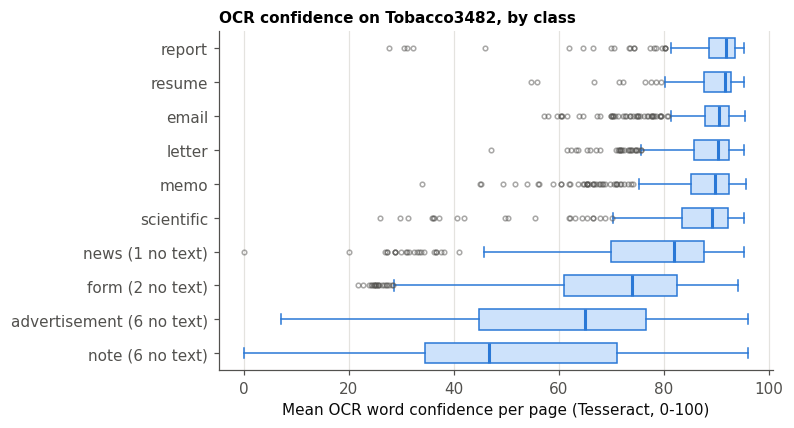

In [16]:
conf = tobacco.dropna(subset=['mean_confidence'])
order = conf.groupby('doc_type').mean_confidence.median().sort_values().index
no_text = tobacco.mean_confidence.isna().groupby(tobacco.doc_type).sum()
labels_with_counts = [f'{c} ({no_text[c]} no text)' if no_text[c] else c for c in order]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot([conf.loc[conf.doc_type == c, 'mean_confidence'] for c in order], orientation='horizontal',
           tick_labels=labels_with_counts, widths=0.6, patch_artist=True,
           boxprops={'facecolor': '#cde2fb', 'edgecolor': BLUE}, medianprops={'color': BLUE, 'linewidth': 2},
           whiskerprops={'color': BLUE}, capprops={'color': BLUE},
           flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': 'none', 'markeredgecolor': INK_2,
                       'alpha': 0.5})
ax.set_xlabel('Mean OCR word confidence per page (Tesseract, 0-100)')
ax.set_title('OCR confidence on Tobacco3482, by class', loc='left')
ax.grid(axis='y', visible=False)
fig.savefig(FIGURES_DIR / 'tobacco_ocr_confidence.png')
plt.show()

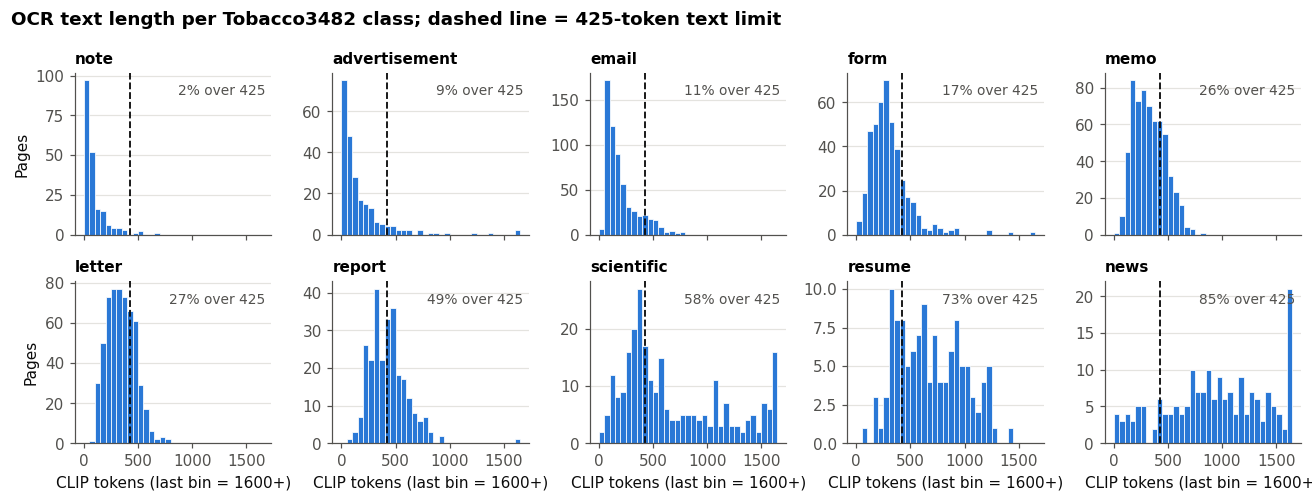

,median,over_limit
doc_type,,
advertisement,90.0,0.09
email,150.0,0.11
form,268.0,0.17
letter,335.0,0.27
memo,314.0,0.26
news,949.5,0.85
note,52.0,0.02
report,415.0,0.49
resume,645.5,0.73


In [17]:
CAP = 1600
classes = tobacco.groupby('doc_type').tokens.median().sort_values().index
fig, axes = plt.subplots(2, 5, figsize=(12, 4.6), sharex=True)
for ax, c in zip(axes.flat, classes):
    tokens = tobacco.loc[tobacco.doc_type == c, 'tokens']
    ax.hist(tokens.clip(upper=CAP), bins=np.arange(0, CAP + 51, 50), color=BLUE, edgecolor='white', linewidth=0.5)
    ax.axvline(LIMIT, color=INK, linestyle='--', linewidth=1.2)
    ax.set_title(c, loc='left')
    ax.text(0.97, 0.93, f'{(tokens > LIMIT).mean():.0%} over {LIMIT}', transform=ax.transAxes, ha='right',
            va='top', fontsize=9, color=INK_2)
    ax.grid(axis='x', visible=False)
for ax in axes[1]:
    ax.set_xlabel(f'CLIP tokens (last bin = {CAP}+)')
for ax in axes[:, 0]:
    ax.set_ylabel('Pages')
fig.suptitle('OCR text length per Tobacco3482 class; dashed line = 425-token text limit', x=0.01,
             ha='left', fontweight='bold')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tobacco_token_length.png')
plt.show()
tobacco.groupby('doc_type').tokens.agg(median='median', over_limit=lambda t: (t > LIMIT).mean()).round(2)

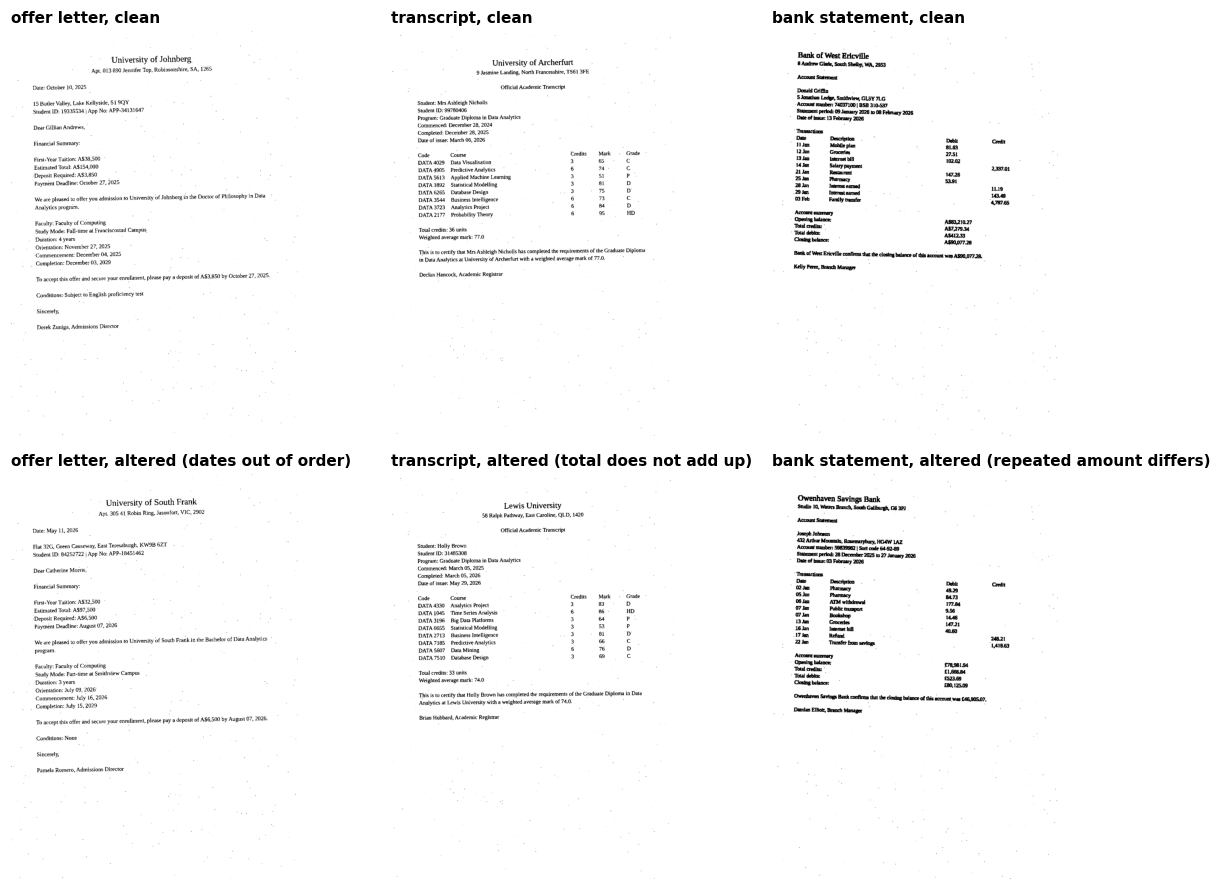

In [18]:
KIND_NAMES = {'altered_date': 'dates out of order', 'altered_amount': 'repeated amount differs',
              'institution_mismatch': 'institution name differs', 'total_mismatch': 'total does not add up'}
SHOWN = {'offer_letter': 'altered_date', 'transcript': 'total_mismatch', 'bank_statement': 'altered_amount'}

fig, axes = plt.subplots(2, 3, figsize=(11, 8.2))
for col, (doc_type, kind) in enumerate(SHOWN.items()):
    altered_rows = sad[(sad.doc_type == doc_type) & (sad.split == 'train') & (sad.inconsistency_type == kind)]
    pair = altered_rows.pair_id.iloc[0]
    for row, label in enumerate(['clean', 'altered']):
        page = sad[(sad.pair_id == pair) & (sad.label == label)].iloc[0]
        ax = axes[row, col]
        ax.imshow(render_job(jobs_by_path[page.image_path]), cmap='gray', vmin=0, vmax=255)
        detail = '' if label == 'clean' else f' ({KIND_NAMES[page.inconsistency_type]})'
        ax.set_title(f'{doc_type.replace("_", " ")}, {label}{detail}', loc='left')
        ax.axis('off')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sad_syn_pairs.png')
plt.show()

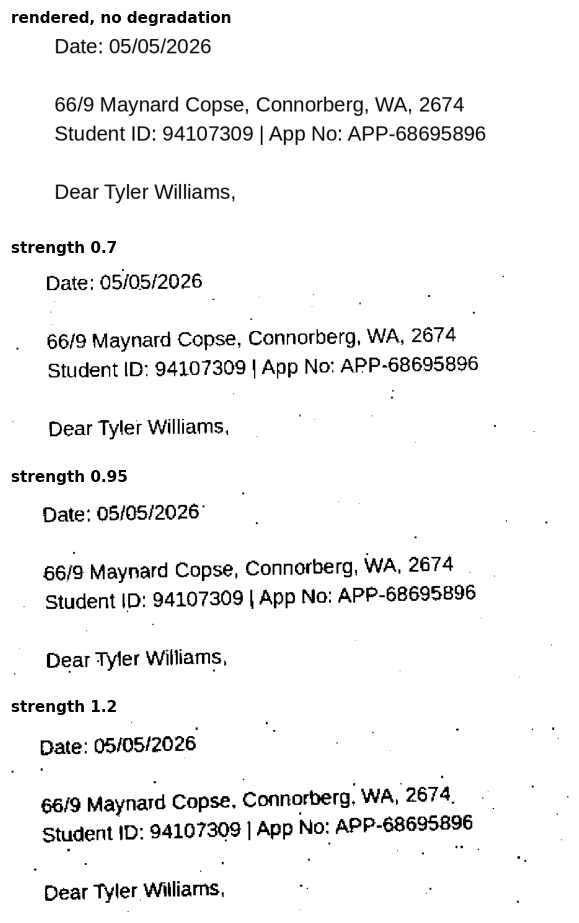

In [19]:
set_seed(3)
kind = DOC_TYPES['offer_letter']
page = render_document(kind.make_clean(), kind.templates[0])
box = (100, 330, 1000, 640)
strengths = [0, 0.7, 0.95, 1.2]
fig, axes = plt.subplots(len(strengths), 1, figsize=(7, 8.5))
for ax, s in zip(axes, strengths):
    ax.imshow(degrade(page, s, seed=10_000).crop(box), cmap='gray', vmin=0, vmax=255)
    ax.set_title('rendered, no degradation' if s == 0 else f'strength {s}', loc='left')
    ax.axis('off')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'sad_syn_degradation.png')
plt.show()

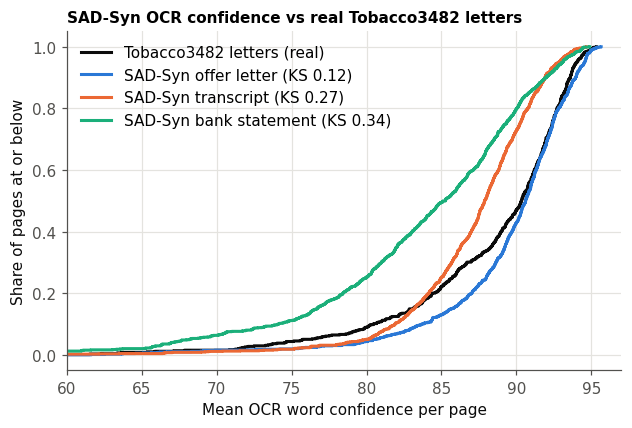

,pages,n,median,ks_vs_tobacco_letters
0,Tobacco3482 letters (real),567,90.338,0.000
1,offer letter,1000,90.616,0.117
2,transcript,1000,87.882,0.265
3,bank statement,1000,85.185,0.341


In [20]:
from scipy.stats import ks_2samp

reference = tobacco.loc[tobacco.doc_type == 'letter', 'mean_confidence'].dropna()
series = [('Tobacco3482 letters (real)', reference, INK)]
for doc_type, colour in zip(['offer_letter', 'transcript', 'bank_statement'], [BLUE, ORANGE, AQUA]):
    series.append((doc_type.replace('_', ' '), sad.loc[sad.doc_type == doc_type, 'mean_confidence'], colour))

fig, ax = plt.subplots(figsize=(6.5, 4))
rows = []
for name, values, colour in series:
    x = np.sort(values)
    ks = ks_2samp(values, reference).statistic
    label = name if values is reference else f'SAD-Syn {name} (KS {ks:.2f})'
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', color=colour, linewidth=2, label=label)
    rows.append({'pages': name, 'n': len(values), 'median': np.median(values), 'ks_vs_tobacco_letters': ks})
ax.set_xlim(60, 97)
ax.set_xlabel('Mean OCR word confidence per page')
ax.set_ylabel('Share of pages at or below')
ax.set_title('SAD-Syn OCR confidence vs real Tobacco3482 letters', loc='left')
ax.legend(frameon=False, loc='upper left')
fig.savefig(FIGURES_DIR / 'sad_syn_confidence_cdf.png')
plt.show()
pd.DataFrame(rows).round(3)